# FleetLogix · Avance 4 — Arquitectura en la nube (AWS)

**Proyecto Integrador M2 · Data Science** — Laura Garmendia

Según la consigna, el foco de este avance es **comprender y documentar la arquitectura, no implementarla**. El análisis completo está en `3. Documentación/AWS_Análisis_Arquitectura.pdf`. Este notebook es la **maqueta local** que lo respalda: ejecuta la lógica de las funciones Lambda en la computadora, sin cuenta de AWS, contra los datos reales de la base `fleetlogix`.

| Archivo | Contenido |
|---|---|
| `2. Scripts/aws_architecture_diagram.png` | Diagrama de la arquitectura propuesta |
| `2. Scripts/lambda_functions/lambda_functions.py` | Funciones Lambda de base, sin cambios |
| `2. Scripts/lambda_functions/lambda_functions_propuesta.py` | Versión ajustada, probada en esta maqueta |
| `3. Documentación/AWS_Análisis_Arquitectura.pdf` | Análisis de la arquitectura (preguntas a, b y c, monitoreo, seguridad y costos) |
| `3. Documentación/fleetlogix_estimacion_aws.csv` | Estimación exportada de la AWS Pricing Calculator |

**Cómo funciona la maqueta**

| En AWS | En la maqueta |
|---|---|
| DynamoDB | Tablas en memoria que aplican las mismas reglas que DynamoDB: claves del tipo definido y sin números `float` |
| SNS | Registro de los mensajes publicados |
| Lambda | Las funciones de los dos archivos, importadas tal cual |
| Kinesis | Eventos con el mismo formato (registros en base64) |
| RDS | La base `fleetlogix` local en PostgreSQL (solo lectura) |
| Hora actual | 15/10/2026 12:30, la fecha de referencia de los datos generados en el avance 1 |

## 0. Configuración

In [1]:
import base64
import copy
import importlib.util
import json
import math
import os
import sys
import types
from datetime import datetime, timedelta
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2
from IPython.display import Image, display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 180)

SCRIPTS = Path("..") / "2. Scripts"
DOCS = Path("..") / "3. Documentación"

# Base local en modo solo lectura: la maqueta no modifica datos
pg_conn = psycopg2.connect(host="localhost", database="fleetlogix", user="postgres", port=5432,
                           password=getpass("Contraseña de PostgreSQL: "))
pg_conn.set_session(readonly=True)   # la base rechaza cualquier intento de escribir

def pg(sql):
    "Consulta la base local y devuelve un DataFrame."
    cur = pg_conn.cursor()
    cur.execute(sql)
    cols = [c[0] for c in cur.description]
    df = pd.DataFrame(cur.fetchall(), columns=cols)
    cur.close()
    return df

MOMENTO = datetime(2026, 10, 15, 12, 30)   # "ahora" en la maqueta
print("PostgreSQL:", pg("SELECT version()").iloc[0, 0].split(",")[0])

PostgreSQL: PostgreSQL 16.15 (Debian 16.15-1.pgdg13+2) on aarch64-unknown-linux-gnu


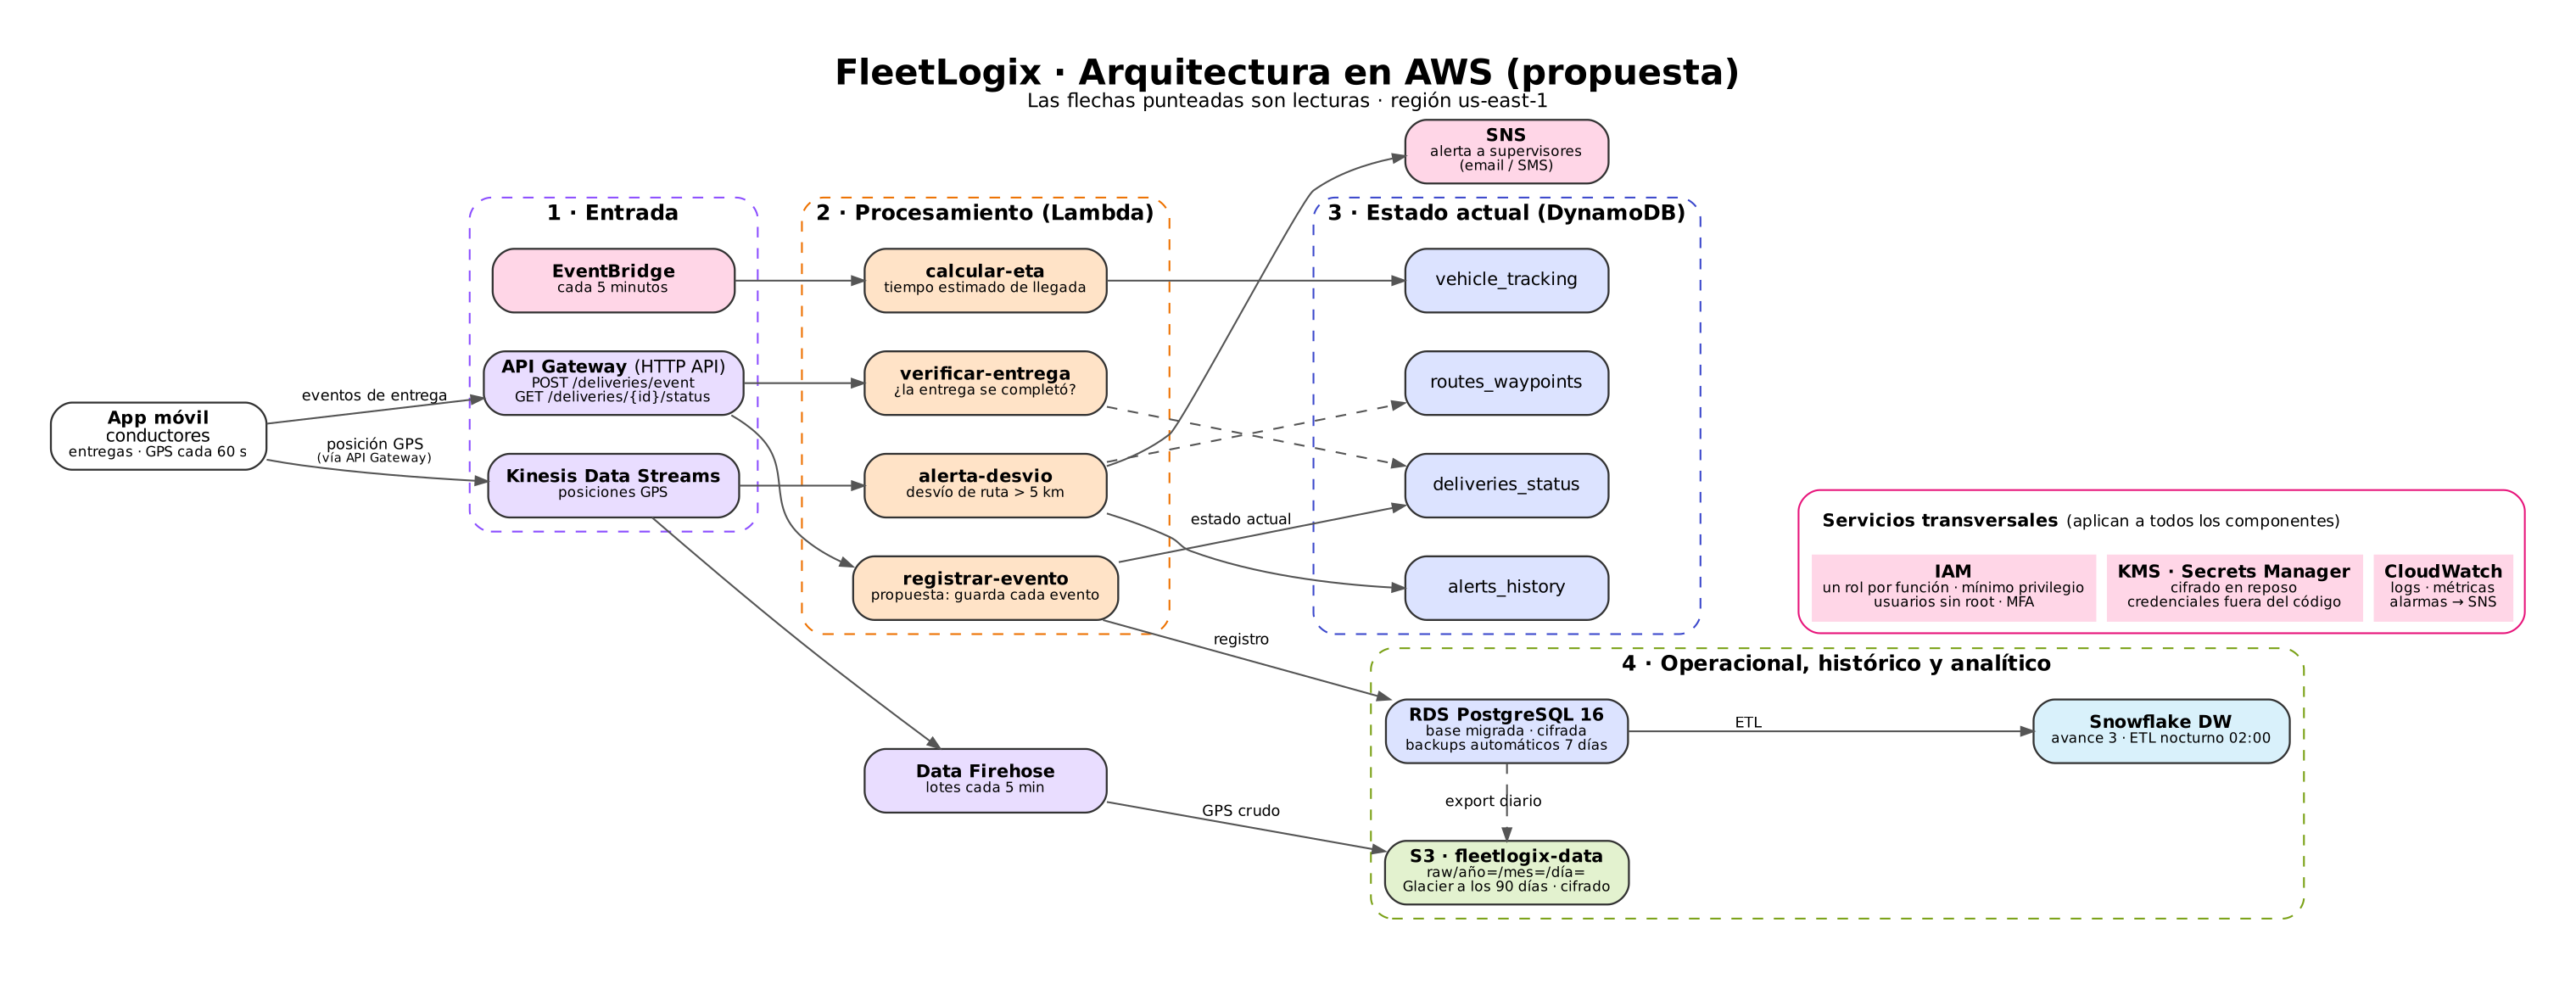

In [2]:
display(Image(filename=str(SCRIPTS / "aws_architecture_diagram.png"), width=1000))

## 1. Maqueta de AWS

Para validar las funciones sin cuenta de AWS, se simularon DynamoDB y SNS con objetos que aplican sus mismas reglas (**técnica de mocks**). Así aparecieron errores que no se ven leyendo el código.

Las tablas en memoria reproducen dos reglas de DynamoDB que importan para este análisis:
- la clave tiene que ser del tipo definido en la tabla (en las 4 tablas de `aws_setup.py`, texto: tipo `S`);
- no se aceptan números `float` de Python, solo `Decimal`; es el mismo error que devuelve boto3.

SNS solo acepta publicar en el tema que existe en la cuenta.

In [3]:
class ErrorAWS(Exception):
    pass

class TablaDynamo:
    def __init__(self, nombre, claves):
        self.nombre, self.claves, self.items = nombre, claves, {}

    def _sin_float(self, valor):
        if isinstance(valor, float):
            raise TypeError("Float types are not supported. Use Decimal types instead.")
        if isinstance(valor, dict):
            for v in valor.values(): self._sin_float(v)
        if isinstance(valor, list):
            for v in valor: self._sin_float(v)

    def _clave(self, key):
        for k in self.claves:
            if not isinstance(key.get(k), str):
                raise ErrorAWS(f"ValidationException: The provided key element does not match the schema "
                               f"({self.nombre}.{k} es de tipo S, texto)")
        return tuple(key[k] for k in self.claves)

    def put_item(self, Item):
        self._sin_float(Item)
        self.items[self._clave(Item)] = copy.deepcopy(Item)

    def get_item(self, Key):
        item = self.items.get(self._clave(Key))
        return {"Item": copy.deepcopy(item)} if item else {}

    def scan(self, **kw):
        return {"Items": [copy.deepcopy(i) for i in self.items.values()]}

class RecursoDynamo:
    def __init__(self, tablas):
        self.tablas = {t.nombre: t for t in tablas}
    def Table(self, nombre):
        if nombre not in self.tablas:
            raise ErrorAWS(f"ResourceNotFoundException: tabla {nombre} inexistente")
        return self.tablas[nombre]

class ClienteSNS:
    def __init__(self, temas):
        self.temas, self.publicados = set(temas), []
    def publish(self, TopicArn, Message, Subject=""):
        if TopicArn not in self.temas:
            raise ErrorAWS(f"NotFound: el tema {TopicArn} no existe en la cuenta")
        self.publicados.append({"tema": TopicArn, "asunto": Subject, **json.loads(Message)})
        return {"MessageId": str(len(self.publicados))}

TEMA = "arn:aws:sns:us-east-1:CUENTA_FLEETLOGIX:fleetlogix-alerts"
dynamo = RecursoDynamo([
    TablaDynamo("deliveries_status", ["delivery_id"]),
    TablaDynamo("vehicle_tracking", ["vehicle_id", "timestamp"]),
    TablaDynamo("routes_waypoints", ["route_id"]),
    TablaDynamo("alerts_history", ["vehicle_id", "timestamp"]),
])
sns = ClienteSNS([TEMA])

# boto3 simulado: las funciones Lambda lo importan sin saber que es una maqueta
boto3_falso = types.ModuleType("boto3")
boto3_falso.resource = lambda servicio, **kw: dynamo
boto3_falso.client = lambda servicio, **kw: sns
sys.modules["boto3"] = boto3_falso
os.environ["ALERTS_TOPIC_ARN"] = TEMA

def cargar(nombre, archivo):
    spec = importlib.util.spec_from_file_location(nombre, SCRIPTS / "lambda_functions" / archivo)
    modulo = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(modulo)
    return modulo

base = cargar("lambda_base", "lambda_functions.py")
prop = cargar("lambda_propuesta", "lambda_functions_propuesta.py")

# Ambas versiones usan la misma hora simulada
class _Ahora(datetime):
    @classmethod
    def now(cls, tz=None):
        return MOMENTO
base.datetime = _Ahora
prop.ahora = lambda: MOMENTO
print("Funciones de base:", [f for f in dir(base) if f.startswith("lambda_")])
print("Funciones propuestas:", ["registrar_evento", "verificar_entrega", "alerta_desvio", "calcular_eta"])

Funciones de base: ['lambda_alerta_desvio', 'lambda_calcular_eta', 'lambda_verificar_entrega']
Funciones propuestas: ['registrar_evento', 'verificar_entrega', 'alerta_desvio', 'calcular_eta']


## 2. Datos de la maqueta

- **`deliveries_status`:** el estado actual de las entregas de los viajes que salieron desde el 14/10/2026, tomado de la base local.
- **`routes_waypoints`:** el recorrido de las 50 rutas. En AWS, los puntos vendrían del trazado real de la carretera; en la maqueta se reparten 40 puntos en línea recta entre las coordenadas de las ciudades, y la distancia por carretera de cada ruta se toma de la base.

In [4]:
entregas = pg('''
    SELECT d.delivery_id, d.trip_id, d.tracking_number, d.delivery_status,
           d.scheduled_datetime, d.delivered_datetime
    FROM deliveries d JOIN trips t ON t.trip_id = d.trip_id
    WHERE t.departure_datetime >= '2026-10-14'
''')
for r in entregas.itertuples():
    dynamo.Table("deliveries_status").put_item(Item={
        "delivery_id": str(r.delivery_id), "trip_id": int(r.trip_id),
        "tracking_number": r.tracking_number, "status": r.delivery_status,
        "scheduled_datetime": str(r.scheduled_datetime),
        "delivered_datetime": None if pd.isna(r.delivered_datetime) else str(r.delivered_datetime),
    })

CIUDADES = {   # coordenadas aproximadas del centro de cada ciudad
    "Bogotá": (4.7110, -74.0721), "Medellín": (6.2442, -75.5812), "Cali": (3.4516, -76.5320),
    "Barranquilla": (10.9685, -74.7813), "Cartagena": (10.3910, -75.4794),
}
rutas = pg("SELECT route_id, route_code, origin_city, destination_city, distance_km, estimated_duration_hours FROM routes")
N_PUNTOS = 40

def punto_en_linea(origen, destino, f):
    (la1, lo1), (la2, lo2) = CIUDADES[origen], CIUDADES[destino]
    return {"lat": la1 + (la2 - la1) * f, "lon": lo1 + (lo2 - lo1) * f}

for r in rutas.itertuples():
    puntos = [punto_en_linea(r.origin_city, r.destination_city, i / (N_PUNTOS - 1)) for i in range(N_PUNTOS)]
    dynamo.Table("routes_waypoints").put_item(Item=prop.a_decimal({
        "route_id": str(r.route_id), "route_code": r.route_code, "waypoints": puntos,
        "distance_km": float(r.distance_km), "estimated_duration_hours": float(r.estimated_duration_hours),
    }))

rutas["linea_recta_km"] = [prop.haversine_km(dict(zip(("lat", "lon"), CIUDADES[o])), dict(zip(("lat", "lon"), CIUDADES[d])))
                          for o, d in zip(rutas.origin_city, rutas.destination_city)]
rutas["separacion_puntos_km"] = rutas["linea_recta_km"] / (N_PUNTOS - 1)
rutas["carretera_vs_recta"] = rutas["distance_km"].astype(float) / rutas["linea_recta_km"]
print(f"deliveries_status: {len(dynamo.Table('deliveries_status').items):,} entregas "
      f"({(entregas.delivery_status == 'pending').sum()} pendientes)")
print(f"routes_waypoints: {len(rutas)} rutas")
rutas[["linea_recta_km", "separacion_puntos_km", "carretera_vs_recta"]].describe().loc[["mean", "min", "max"]].round(2)

deliveries_status: 724 entregas (36 pendientes)
routes_waypoints: 50 rutas


,linea_recta_km,separacion_puntos_km,carretera_vs_recta
mean,476.26,12.21,1.46
min,99.71,2.56,1.12
max,857.83,22.00,1.92


La distancia por carretera es en promedio bastante mayor que la línea recta entre ciudades (ver `carretera_vs_recta`). Este dato importa para el cálculo del ETA (sección 5).

## 3. registrar-evento y verificar-entrega

### 3.1 La función verificar-entrega de base con distintos eventos

Se prueba con una entrega completada, una pendiente y una inexistente, y con los formatos en que puede llegar el pedido: invocación directa (como en las pruebas de la consola), con el número como número, y desde API Gateway.

In [5]:
completada = entregas[entregas.delivery_status == "delivered"].iloc[-1]
pendiente = entregas[entregas.delivery_status == "pending"].iloc[0]
id_ok, id_pend = str(completada.delivery_id), str(pendiente.delivery_id)

casos = [
    ("Directo, id como texto (completada)", {"delivery_id": id_ok}),
    ("Directo, id como texto (pendiente)", {"delivery_id": id_pend}),
    ("Directo, id como número", {"delivery_id": int(id_ok)}),
    ("API Gateway GET /deliveries/{id}/status", {"pathParameters": {"id": id_ok}}),
    ("API Gateway POST con body JSON", {"body": json.dumps({"delivery_id": id_ok})}),
    ("Entrega inexistente", {"delivery_id": "999999"}),
    ("Sin delivery_id", {}),
]

def resumen(r):
    cuerpo = json.loads(r["body"])
    if "error" in cuerpo:
        return f"{r['statusCode']} · {cuerpo['error'][:70]}"
    return f"{r['statusCode']} · status={cuerpo['status']} · completada={cuerpo['is_completed']}"

pd.DataFrame([{"caso": n,
               "versión de base": resumen(base.lambda_verificar_entrega(e, None)),
               "versión propuesta": resumen(prop.verificar_entrega(e))} for n, e in casos])

,caso,versión de base,versión propuesta
0,"Directo, id como texto (completada)",200 · status=delivered · completada=True,200 · status=delivered · completada=True
1,"Directo, id como texto (pendiente)",200 · status=pending · completada=False,200 · status=pending · completada=False
2,"Directo, id como número",500 · ValidationException: The provided key el...,200 · status=delivered · completada=True
3,API Gateway GET /deliveries/{id}/status,400 · delivery_id es requerido,200 · status=delivered · completada=True
4,API Gateway POST con body JSON,400 · delivery_id es requerido,200 · status=delivered · completada=True
5,Entrega inexistente,404 · Entrega no encontrada,404 · Entrega no encontrada
6,Sin delivery_id,400 · delivery_id es requerido,400 · delivery_id es requerido


- Con el id como texto, las dos versiones responden igual.
- **Con el id como número** (como está en PostgreSQL), la versión de base falla con 500: DynamoDB rechaza la clave porque la tabla la define como texto.
- **Desde API Gateway**, la versión de base responde 400: busca `delivery_id` como campo suelto del evento, pero API Gateway lo envía dentro de `pathParameters` o del `body`. En la práctica, la función solo funciona en las pruebas desde la consola.
- La versión propuesta resuelve los tres casos sin cambiar la lógica de fondo.

### 3.2 Flujo de punta a punta: un conductor completa una entrega

La función propuesta `registrar-evento` guarda el evento que envía la app. Después, `verificar-entrega` la informa como completada. (En la maqueta, el registro en RDS queda desactivado para no modificar la base local.)

In [6]:
evento_app = {"body": json.dumps({"delivery_id": id_pend, "trip_id": int(pendiente.trip_id),
                                  "tracking_number": pendiente.tracking_number,
                                  "status": "delivered", "timestamp": "2026-10-15T12:28:00"})}
antes = json.loads(prop.verificar_entrega({"pathParameters": {"id": id_pend}})["body"])
registro = prop.registrar_evento(evento_app)
despues = json.loads(prop.verificar_entrega({"pathParameters": {"id": id_pend}})["body"])
pd.DataFrame([{"momento": "antes del evento", **antes},
              {"momento": "registrar-evento", "status": json.loads(registro["body"])["status"],
               "delivered_datetime": json.loads(registro["body"])["delivered_datetime"]},
              {"momento": "después del evento", **despues}])

,momento,delivery_id,tracking_number,is_completed,status,delivered_datetime
0,antes del evento,399767,FL202600399767,False,pending,NaN
1,registrar-evento,NaN,NaN,NaN,delivered,2026-10-15T12:28:00
2,después del evento,399767,FL202600399767,True,delivered,2026-10-15T12:28:00


## 4. alerta-desvio

### 4.1 Posiciones de los camiones en ruta

A las 12:30 del 15/10 hay 19 viajes en curso (estado `in_progress`). Varios ya superaron su hora de llegada planificada, es decir, vienen atrasados. Para cada uno se simula su posición sobre la ruta según el tiempo transcurrido, con un ritmo propio entre 1,3 y 1,9 veces la duración planificada. A **un camión se lo desplaza 12 km hacia un costado de la ruta** para simular un desvío.

In [7]:
viajes = pg('''
    SELECT t.trip_id, t.vehicle_id, t.driver_id, t.route_id, t.departure_datetime,
           r.origin_city, r.destination_city, r.distance_km, r.estimated_duration_hours
    FROM trips t JOIN routes r ON r.route_id = t.route_id
    WHERE t.status = 'in_progress'
    ORDER BY t.departure_datetime
''')
viajes["departure_datetime"] = pd.to_datetime(viajes["departure_datetime"])
viajes["duracion_plan_h"] = viajes["estimated_duration_hours"].astype(float)
rng = np.random.default_rng(42)
viajes["ritmo"] = rng.uniform(1.3, 1.9, len(viajes))   # >1: más lento que lo planificado
transcurrido_h = (MOMENTO - viajes["departure_datetime"]).dt.total_seconds() / 3600
viajes["avance"] = np.minimum(transcurrido_h / (viajes["duracion_plan_h"] * viajes["ritmo"]), 0.98)

posiciones = []
for i, v in enumerate(viajes.itertuples()):
    p = punto_en_linea(v.origin_city, v.destination_city, v.avance)
    if i == 0:                                          # 12 km hacia un costado, perpendicular a la ruta
        (la1, lo1), (la2, lo2) = CIUDADES[v.origin_city], CIUDADES[v.destination_city]
        dx, dy = (lo2 - lo1) * 111.32 * math.cos(math.radians(p["lat"])), (la2 - la1) * 110.57
        largo = math.hypot(dx, dy)
        p["lon"] += (-dy / largo) * 12 / (111.32 * math.cos(math.radians(p["lat"])))
        p["lat"] += (dx / largo) * 12 / 110.57
    posiciones.append({"vehicle_id": str(v.vehicle_id), "driver_id": str(v.driver_id),
                       "route_id": str(v.route_id), "lat": round(p["lat"], 6), "lon": round(p["lon"], 6),
                       "timestamp": MOMENTO.isoformat(timespec="seconds")})
print(f"{len(viajes)} viajes en curso · vehículo desviado: {posiciones[0]['vehicle_id']}")
viajes[["trip_id", "vehicle_id", "origin_city", "destination_city", "avance"]].head()

19 viajes en curso · vehículo desviado: 58


,trip_id,vehicle_id,origin_city,destination_city,avance
0,99941,58,Bogotá,Cartagena,0.669194
1,99942,140,Bogotá,Cartagena,0.752920
2,99956,199,Cali,Barranquilla,0.667160
3,99958,188,Cartagena,Cali,0.783471
4,99963,17,Bogotá,Cartagena,0.808675


### 4.2 Versión de base

In [8]:
r = base.lambda_alerta_desvio({"vehicle_id": posiciones[1]["vehicle_id"], "route_id": posiciones[1]["route_id"],
                               "driver_id": posiciones[1]["driver_id"],
                               "current_location": {"lat": posiciones[1]["lat"], "lon": posiciones[1]["lon"]}}, None)
print(r["statusCode"], json.loads(r["body"]))

500 {'error': "unsupported operand type(s) for -: 'decimal.Decimal' and 'float'"}


La versión de base falla antes de calcular nada: DynamoDB devuelve los números como `Decimal` y la posición llega como `float`, y Python no permite restarlos. Para ver qué habría decidido si ese error se corrigiera, se aplica su misma lógica por separado: la distancia al **punto más cercano** de la ruta, con 111 km por grado.

In [9]:
def desvio_logica_base(pos):
    puntos = dynamo.Table("routes_waypoints").get_item(Key={"route_id": pos["route_id"]})["Item"]["waypoints"]
    return min(math.hypot(float(w["lat"]) - pos["lat"], float(w["lon"]) - pos["lon"]) * 111 for w in puntos)

evento_kinesis = {"Records": [{"kinesis": {"data": base64.b64encode(json.dumps(p).encode()).decode()}}
                              for p in posiciones]}
resultado = prop.alerta_desvio(evento_kinesis)

comparacion = pd.DataFrame([{
    "vehicle_id": p["vehicle_id"],
    "ruta": f"{v.origin_city} → {v.destination_city}",
    "desvío base (al punto) km": round(desvio_logica_base(p), 1),
    "alerta base": desvio_logica_base(p) > 5,
    "desvío propuesta (al tramo) km": r["deviation_km"],
    "alerta propuesta": r["alert_sent"],
} for p, v, r in zip(posiciones, viajes.itertuples(), resultado["resultados"])])
comparacion

,vehicle_id,ruta,desvío base (al punto) km,alerta base,desvío propuesta (al tramo) km,alerta propuesta
0,58,Bogotá → Cartagena,12.2,True,12.0,True
1,140,Bogotá → Cartagena,6.1,True,0.0,False
2,199,Cali → Barranquilla,0.4,False,0.0,False
3,188,Cartagena → Cali,8.9,True,0.0,False
4,17,Bogotá → Cartagena,7.7,True,0.0,False
5,96,Cali → Barranquilla,2.6,False,0.0,False
6,112,Bogotá → Cartagena,2.1,False,0.0,False
7,81,Cali → Barranquilla,2.3,False,0.0,False
8,59,Cali → Barranquilla,2.8,False,0.0,False
9,192,Cartagena → Bogotá,5.6,True,0.0,False


In [10]:
print(f"Alertas con la lógica de base: {comparacion['alerta base'].sum()} de {len(comparacion)} camiones")
print(f"Alertas con la propuesta:      {comparacion['alerta propuesta'].sum()} de {len(comparacion)} camiones")
print(f"Mensajes publicados en SNS:    {len(sns.publicados)}")

Alertas con la lógica de base: 9 de 19 camiones
Alertas con la propuesta:      1 de 19 camiones
Mensajes publicados en SNS:    1


Con los puntos de la ruta separados unos 15-20 km, un camión que va exactamente sobre la ruta puede quedar a más de 5 km del punto más cercano: la lógica de base genera **falsas alarmas** con camiones que no se desviaron. Medir la distancia al **tramo** entre dos puntos detecta solo el desvío real.

### 4.3 Un desvío que dura varios minutos

El camión desviado sigue enviando su posición cada minuto. La versión de base enviaría una alerta por cada posición; la propuesta avisa una vez y espera 30 minutos antes de volver a avisar por el mismo vehículo.

In [11]:
desviado = posiciones[0]
seguimiento = [{"minuto": 0, "desvío km": resultado["resultados"][0]["deviation_km"],
                "alerta enviada": resultado["resultados"][0]["alert_sent"]}]
for minuto in range(1, 6):
    pos = {**desviado, "timestamp": (MOMENTO + timedelta(minutes=minuto)).isoformat(timespec="seconds")}
    r = prop.alerta_desvio(pos)["resultados"][0]
    seguimiento.append({"minuto": minuto, "desvío km": r["deviation_km"], "alerta enviada": r["alert_sent"]})
print(f"Mensajes en SNS para el vehículo {desviado['vehicle_id']}: "
      f"{sum(m['vehicle_id'] == desviado['vehicle_id'] for m in sns.publicados)}")
pd.DataFrame(seguimiento)

Mensajes en SNS para el vehículo 58: 1


,minuto,desvío km,alerta enviada
0,0,12.0,True
1,1,12.0,False
2,2,12.0,False
3,3,12.0,False
4,4,12.0,False
5,5,12.0,False


In [12]:
# Además, la versión de base publica en un tema de ejemplo (cuenta 123456789012), que no existe en la cuenta:
try:
    sns.publish(TopicArn="arn:aws:sns:us-east-1:123456789012:fleetlogix-alerts", Message="{}")
except ErrorAWS as e:
    print("Error:", e)

Error: NotFound: el tema arn:aws:sns:us-east-1:123456789012:fleetlogix-alerts no existe en la cuenta


## 5. calcular-eta

### 5.1 Versión de base

In [13]:
v0, p0 = viajes.iloc[1], posiciones[1]
destino = dict(zip(("lat", "lon"), CIUDADES[v0.destination_city]))
r = base.lambda_calcular_eta({"vehicle_id": p0["vehicle_id"], "current_location": {"lat": p0["lat"], "lon": p0["lon"]},
                              "destination": destino, "current_speed_kmh": 60}, None)
print(r["statusCode"], json.loads(r["body"]))

500 {'error': 'Float types are not supported. Use Decimal types instead.'}


Calcula el ETA, pero falla al guardarlo: DynamoDB no acepta las coordenadas `float`. Además, programada cada 5 minutos con EventBridge, no recibiría ningún vehículo en el evento y respondería 400.

### 5.2 Comparación de métodos

La versión propuesta se ejecuta como lo haría EventBridge (sin datos en el evento): toma la última posición de cada vehículo, que guardó `alerta-desvio`, y calcula para todos. Se compara con la fórmula de base y con la llegada planificada.

In [14]:
eta = pd.DataFrame(prop.calcular_eta({})["resultados"])
eta["eta"] = pd.to_datetime(eta["eta"])

def eta_logica_base(pos, viaje):
    dest = CIUDADES[viaje.destination_city]
    km = math.hypot(dest[0] - pos["lat"], dest[1] - pos["lon"]) * 111
    return MOMENTO + timedelta(hours=km / 60)

tabla = pd.DataFrame([{
    "vehicle_id": p["vehicle_id"],
    "ruta": f"{v.origin_city} → {v.destination_city}",
    "llegada planificada": v.departure_datetime + timedelta(hours=v.duracion_plan_h),
    "ETA base (recta, 60 km/h)": eta_logica_base(p, v),
} for p, v in zip(posiciones, viajes.itertuples())]).merge(
    eta[["vehicle_id", "distance_remaining_km", "avg_speed_kmh", "eta"]].rename(columns={"eta": "ETA propuesta"}),
    on="vehicle_id")
tabla["base vs plan (h)"] = ((tabla["ETA base (recta, 60 km/h)"] - tabla["llegada planificada"]).dt.total_seconds() / 3600).round(1)
tabla["propuesta vs plan (h)"] = ((tabla["ETA propuesta"] - tabla["llegada planificada"]).dt.total_seconds() / 3600).round(1)
for c in ["llegada planificada", "ETA base (recta, 60 km/h)", "ETA propuesta"]:
    tabla[c] = tabla[c].dt.strftime("%d/%m %H:%M")
tabla

,vehicle_id,ruta,llegada planificada,"ETA base (recta, 60 km/h)",distance_remaining_km,avg_speed_kmh,ETA propuesta,base vs plan (h),propuesta vs plan (h)
0,58,Bogotá → Cartagena,15/10 09:11,15/10 16:05,371.5,61.4,15/10 18:32,6.9,9.3
1,140,Bogotá → Cartagena,15/10 09:15,15/10 15:10,277.5,61.4,15/10 17:00,5.9,7.7
2,199,Cali → Barranquilla,15/10 09:04,15/10 17:15,402.8,74.5,15/10 17:54,8.2,8.8
3,188,Cartagena → Cali,15/10 07:31,15/10 15:18,223.4,71.9,15/10 15:36,7.8,8.1
4,17,Bogotá → Cartagena,15/10 10:49,15/10 14:34,199.3,60.2,15/10 15:48,3.7,5.0
5,96,Cali → Barranquilla,15/10 09:48,15/10 17:56,461.8,74.5,15/10 18:41,8.1,8.9
6,112,Bogotá → Cartagena,15/10 08:37,15/10 15:31,304.0,75.1,15/10 16:32,6.9,7.9
7,81,Cali → Barranquilla,15/10 10:22,15/10 17:39,437.6,74.5,15/10 18:22,7.3,8.0
8,59,Cali → Barranquilla,15/10 13:28,15/10 16:56,367.0,61.9,15/10 18:25,3.5,4.9
9,192,Cartagena → Bogotá,15/10 09:17,15/10 14:54,244.6,75.8,15/10 15:43,5.6,6.4


In [15]:
print(f"Ritmo simulado de los camiones: entre {viajes['ritmo'].min():.2f} y {viajes['ritmo'].max():.2f} veces la duración planificada")
print(f"Diferencia promedio con el plan · base: {tabla['base vs plan (h)'].mean():+.1f} h · propuesta: {tabla['propuesta vs plan (h)'].mean():+.1f} h")
print(f"La fórmula de base anuncia la llegada en promedio "
      f"{(tabla['propuesta vs plan (h)'] - tabla['base vs plan (h)']).mean():.1f} h antes que la propuesta")

Ritmo simulado de los camiones: entre 1.34 y 1.89 veces la duración planificada
Diferencia promedio con el plan · base: +5.4 h · propuesta: +6.8 h
La fórmula de base anuncia la llegada en promedio 1.4 h antes que la propuesta


- La **fórmula de base** mide en línea recta y supone 60 km/h. Como la distancia por carretera es bastante mayor que la recta, el ETA queda sistemáticamente **antes** de lo posible: anunciaría llegadas que no van a ocurrir.
- La **propuesta** usa la distancia por carretera que falta y la velocidad media de la ruta (distancia ÷ duración estimada). Como estos camiones vienen atrasados, su ETA queda **después** del plan: es la información útil para avisar al cliente con tiempo.
- Aun así, la propuesta supone que desde ahora el camión irá a la velocidad media de la ruta, y estos camiones vienen más lentos. La mejora siguiente sería usar la velocidad real de las últimas posiciones o las velocidades históricas por ruta y turno del Data Warehouse del avance 3.

## 6. Migración a RDS: qué verificar

La migración no se ejecuta (sección 5 del PDF). Dos datos de la base local definen cómo hacerla y cómo controlarla:

In [16]:
version = pg("SHOW server_version").iloc[0, 0]
print(f"Versión de la base local: PostgreSQL {version} → RDS tiene que crearse en la versión 16, no en 15.4 como en aws_setup.py")
conteos = pg('''
    SELECT 'vehicles' AS tabla, COUNT(*) AS filas FROM vehicles
    UNION ALL SELECT 'drivers', COUNT(*) FROM drivers
    UNION ALL SELECT 'routes', COUNT(*) FROM routes
    UNION ALL SELECT 'trips', COUNT(*) FROM trips
    UNION ALL SELECT 'deliveries', COUNT(*) FROM deliveries
    UNION ALL SELECT 'maintenance', COUNT(*) FROM maintenance
''')
conteos.loc[len(conteos)] = ["Total", conteos["filas"].astype(int).sum()]
conteos

Versión de la base local: PostgreSQL 16.15 (Debian 16.15-1.pgdg13+2) → RDS tiene que crearse en la versión 16, no en 15.4 como en aws_setup.py


,tabla,filas
0,vehicles,200
1,drivers,400
2,routes,50
3,trips,100000
4,deliveries,400000
5,maintenance,5000
6,Total,505650


Después de restaurar en RDS, la misma consulta tiene que devolver los mismos números, y las 31 validaciones del avance 1 tienen que dar OK. Comandos propuestos:

```bash
docker exec postgres pg_dump -U postgres -d fleetlogix -Fc --no-owner --no-privileges > fleetlogix.dump
psql "host=$RDS_ENDPOINT user=fleetlogix_admin dbname=postgres sslmode=require" -c "CREATE DATABASE fleetlogix;"
pg_restore -h $RDS_ENDPOINT -U fleetlogix_admin -d fleetlogix --no-owner -j 4 fleetlogix.dump
```

## 7. Costos

Estimación hecha con la AWS Pricing Calculator ([ver estimación](https://calculator.aws/#/estimate?id=033a8e3173b6e136d9389bc7758012aed2b26d67)), exportada a `fleetlogix_estimacion_aws.csv`. Los supuestos de volumen están en la sección 8 del PDF.

In [17]:
lineas = (DOCS / "fleetlogix_estimacion_aws.csv").read_text(encoding="utf-8-sig").splitlines()
inicio = next(i for i, l in enumerate(lineas) if l.startswith("Jerarquía de grupos"))
fin = next(i for i in range(inicio + 1, len(lineas)) if not lineas[i].strip())
import io
costos = pd.read_csv(io.StringIO("\n".join(lineas[inicio:fin])))
costos = costos.groupby("Servicio", as_index=False)["Mensual"].sum()
FIJOS = {"Amazon RDS for PostgreSQL", "Amazon Kinesis Data Streams", "AWS Secrets Manager"}
costos["tipo"] = np.where(costos["Servicio"].isin(FIJOS), "fijo (encendido 24 h)", "variable (por uso)")
costos = costos.sort_values("Mensual", ascending=False).reset_index(drop=True)
costos["%"] = (100 * costos["Mensual"] / costos["Mensual"].sum()).round(1)
anual = lineas[2].split(",")[2]   # resumen de la calculadora: inicial, mensual, 12 meses
print(f"Total: US$ {costos['Mensual'].sum():.2f} por mes · US$ {anual} por año (según la calculadora)")
costos.groupby("tipo")[["Mensual", "%"]].sum().round(2)

Total: US$ 35.71 por mes · US$ 428.52 por año (según la calculadora)


,Mensual,%
tipo,,
fijo (encendido 24 h),25.40,71.0
variable (por uso),10.31,29.0


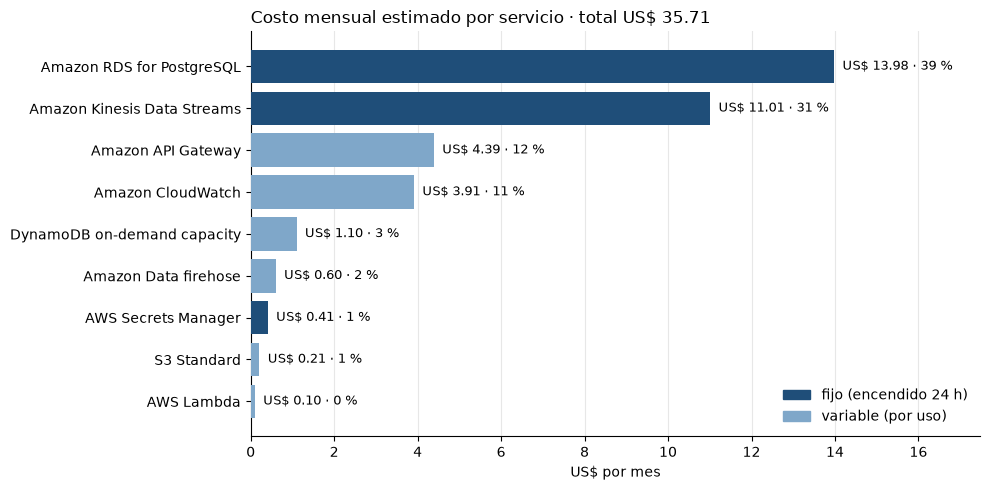

In [18]:
visibles = costos[costos["Mensual"] > 0].iloc[::-1]
colores = np.where(visibles["tipo"].str.startswith("fijo"), "#1F4E79", "#7FA7C9")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(visibles["Servicio"], visibles["Mensual"], color=colores, zorder=3)
for y, (v, p) in enumerate(zip(visibles["Mensual"], visibles["%"])):
    ax.text(v + 0.2, y, f"US$ {v:.2f} · {p:.0f} %", va="center", fontsize=9)
ax.set_title(f"Costo mensual estimado por servicio · total US$ {costos['Mensual'].sum():.2f}", loc="left")
ax.set_xlabel("US$ por mes")
ax.grid(axis="x", alpha=0.3, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.25)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#1F4E79", label="fijo (encendido 24 h)"), Patch(color="#7FA7C9", label="variable (por uso)")],
          loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

Tres servicios que cobran por estar encendidos (RDS, el shard de Kinesis y el secreto) suman el 71 % del costo; los que cobran por uso, el 29 %. Los servicios por uso convienen cuando el tráfico es bajo o irregular; la capacidad reservada, cuando el uso es alto y predecible. Por eso Kinesis va en modo aprovisionado (US$ 11,01 frente a US$ 29,53 bajo demanda) y el resto del procesamiento es serverless.

## 8. Conclusiones

- **La arquitectura funciona en la maqueta**: las cuatro funciones propuestas se ejecutaron contra los datos reales de FleetLogix, encadenadas como en AWS (la app registra un evento, verificar-entrega lo informa, alerta-desvio guarda posiciones y calcular-eta las usa).
- **Las funciones de base no funcionarían tal como están**: verificar-entrega solo responde en las pruebas de consola; alerta-desvio y calcular-eta fallan por mezclar `Decimal` y `float`; y, corregido eso, alerta-desvio daría falsas alarmas y calcular-eta anunciaría llegadas imposibles.
- **El diseño general es adecuado**: los problemas son de implementación (tipos de datos, formato de los eventos, medición de distancias), no de la elección de servicios.
- **Costo: US$ 35,71 por mes**, por debajo del límite de US$ 50, con un 71 % de costo fijo.
- **Probar sin desplegar** permitió encontrar estos problemas sin cuenta de AWS, sin tarjeta y sin costo, con el mismo criterio de verificar contra la fuente aplicado en los avances anteriores.

In [19]:
pg_conn.close()
print("Conexión cerrada")

Conexión cerrada
